# Mapa de calor y comparación de clasificadores (dataset de vinos)

En esta tarea uso el dataset de vinos de scikit-learn. Lo que hago es:

1. Sacar un mapa de calor de correlaciones y buscar la tercera característica más representativa, además de Alcohol y Flavonoides.
2. Graficar esa característica contra Alcohol y contra Flavonoides.
3. Probar k-NN, Árbol de Decisión y Naive Bayes, y ver cuál se ve más claro al graficar.

## 1. Cargar los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine

datos_vino = load_wine()
X = pd.DataFrame(datos_vino.data, columns=datos_vino.feature_names)
y = pd.Series(datos_vino.target, name="Clase_de_Vino")

# nombres de las columnas en español, como en clase
mapeo_columnas = {
    'alcohol': 'Alcohol', 'malic_acid': 'Acido_Malico', 'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad_Ceniza', 'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles_Totales', 'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles_No_Flavonoides', 'proanthocyanins': 'Proantocianidinas',
    'color_intensity': 'Intensidad_Color', 'hue': 'Matiz',
    'od280/od315_of_diluted_wines': 'OD280_OD315', 'proline': 'Prolina'
}
X.rename(columns=mapeo_columnas, inplace=True)
print(X.shape)

(178, 13)


## 2. Mapa de calor de correlaciones

Puse la clase de vino como una columna más. Así, mirando la última fila, puedo ver qué tan relacionada está cada característica con la clase, que es lo que queremos predecir.

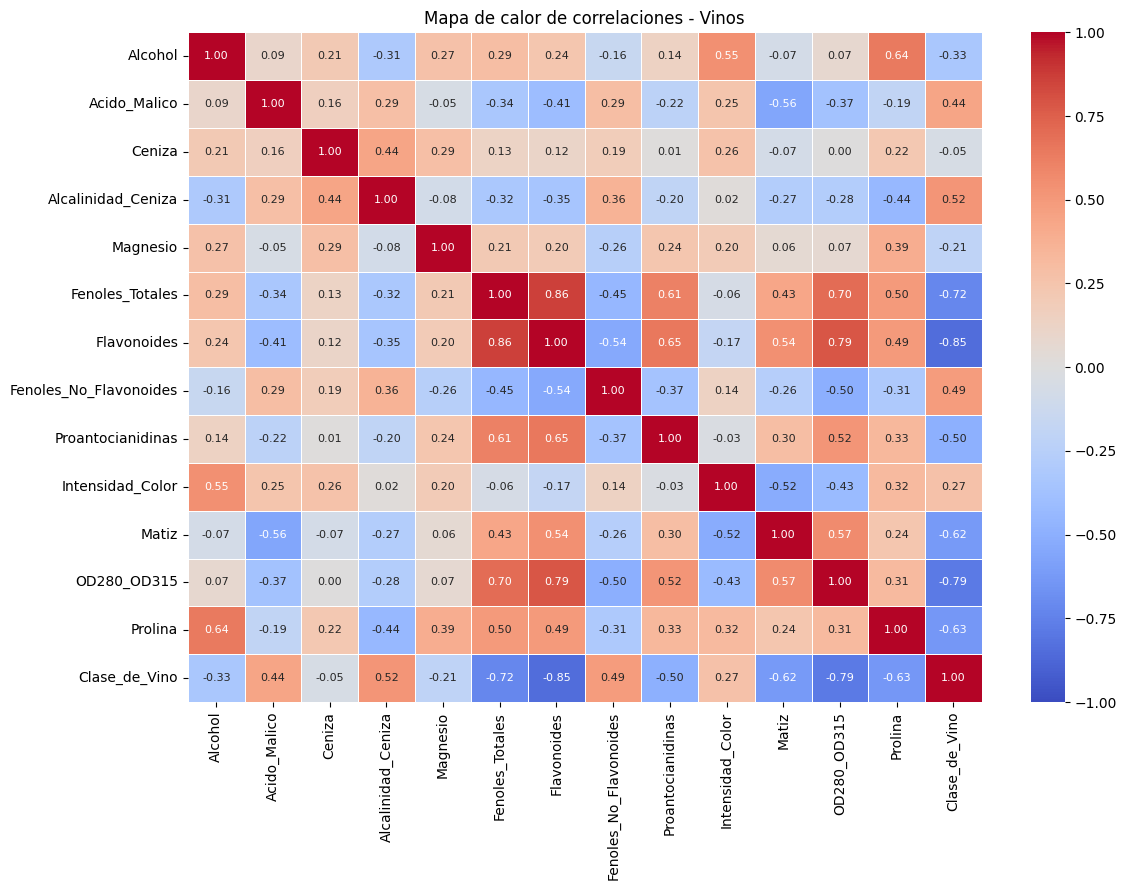

In [2]:
df = X.copy()
df['Clase_de_Vino'] = y
corr = df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 8})
plt.title("Mapa de calor de correlaciones - Vinos")
plt.tight_layout()
plt.show()

Para elegir la tercera característica ordené todas por el valor absoluto de su correlación con la clase. Saqué del ranking a Alcohol y Flavonoides porque ya me las daban en la orden.

Flavonoides               0.847
OD280_OD315               0.788
Fenoles_Totales           0.719
Prolina                   0.634
Matiz                     0.617
Alcalinidad_Ceniza        0.518
Proantocianidinas         0.499
Fenoles_No_Flavonoides    0.489
Acido_Malico              0.438
Alcohol                   0.328
Intensidad_Color          0.266
Magnesio                  0.209
Ceniza                    0.050

Tercera característica: OD280_OD315 | correlación: -0.788


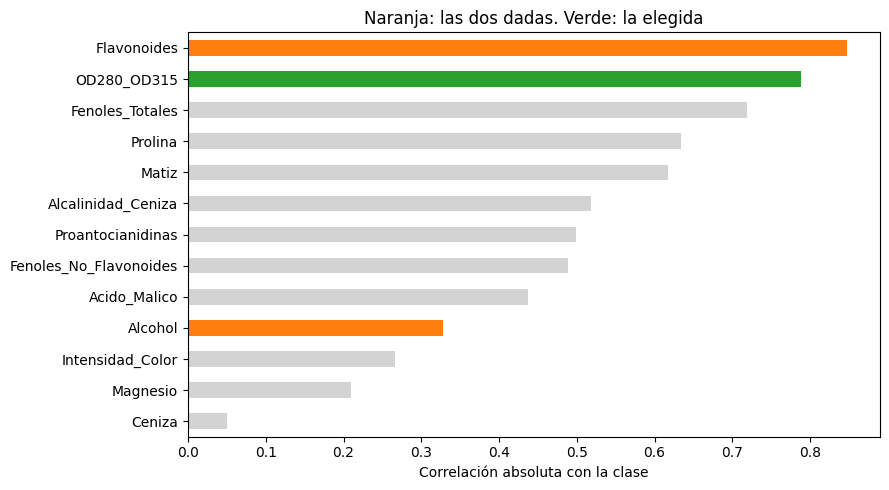

In [3]:
corr_clase = corr['Clase_de_Vino'].drop('Clase_de_Vino')
ranking = corr_clase.abs().sort_values(ascending=False)
print(ranking.round(3).to_string())

tercera = ranking.drop(['Alcohol', 'Flavonoides']).index[0]
print("\nTercera característica:", tercera, "| correlación:", round(corr_clase[tercera], 3))

plt.figure(figsize=(9, 5))
colores = ['tab:green' if c == tercera else ('tab:orange' if c in ['Alcohol', 'Flavonoides'] else 'lightgray')
           for c in ranking.index]
ranking.plot(kind='barh', color=colores)
plt.gca().invert_yaxis()
plt.xlabel('Correlación absoluta con la clase')
plt.title('Naranja: las dos dadas. Verde: la elegida')
plt.tight_layout()
plt.show()

La tercera es **OD280_OD315**, con una correlación de -0.79 con la clase. Flavonoides tiene -0.85 y Alcohol solo -0.33, así que Alcohol no es de las más representativas, pero igual la usamos porque la orden lo pide.

Fenoles_Totales quedaría justo después (0.72), pero está muy ligada a Flavonoides (0.87), o sea que me daría casi la misma información. Por eso me quedo con OD280_OD315.

## 3. Gráficas de pares

Hice los tres pares posibles entre Alcohol, Flavonoides y OD280_OD315. Cada color es una clase de vino.

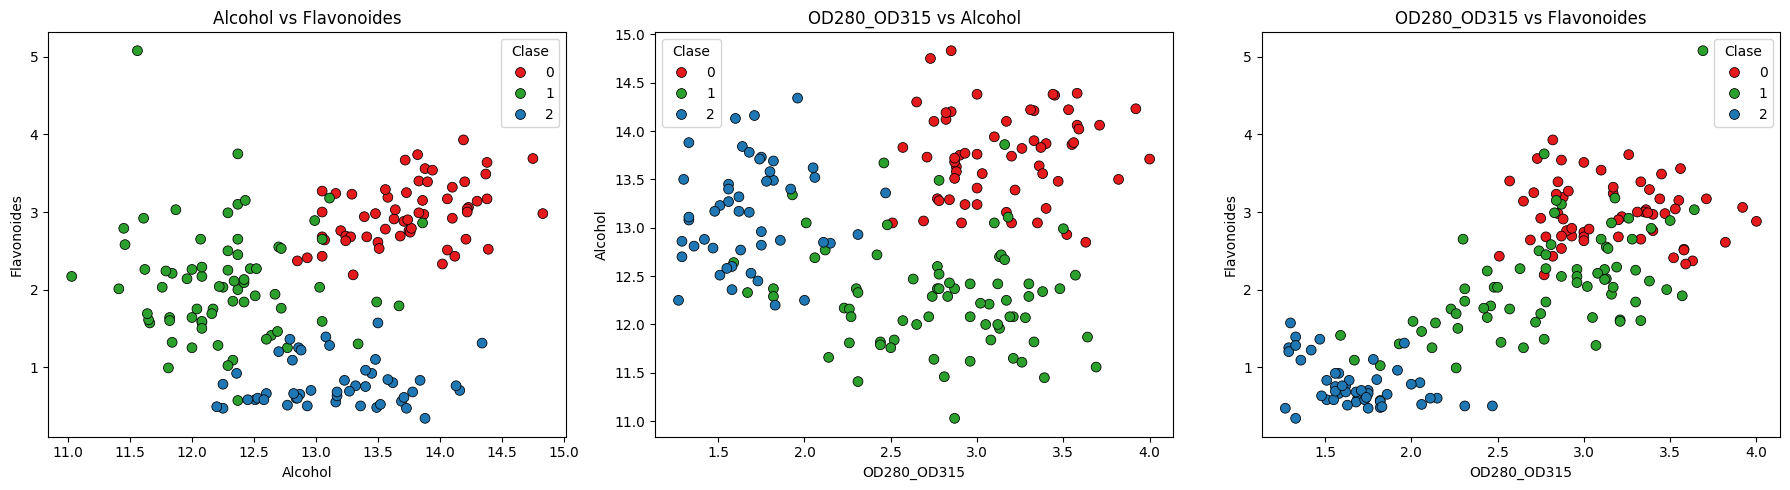

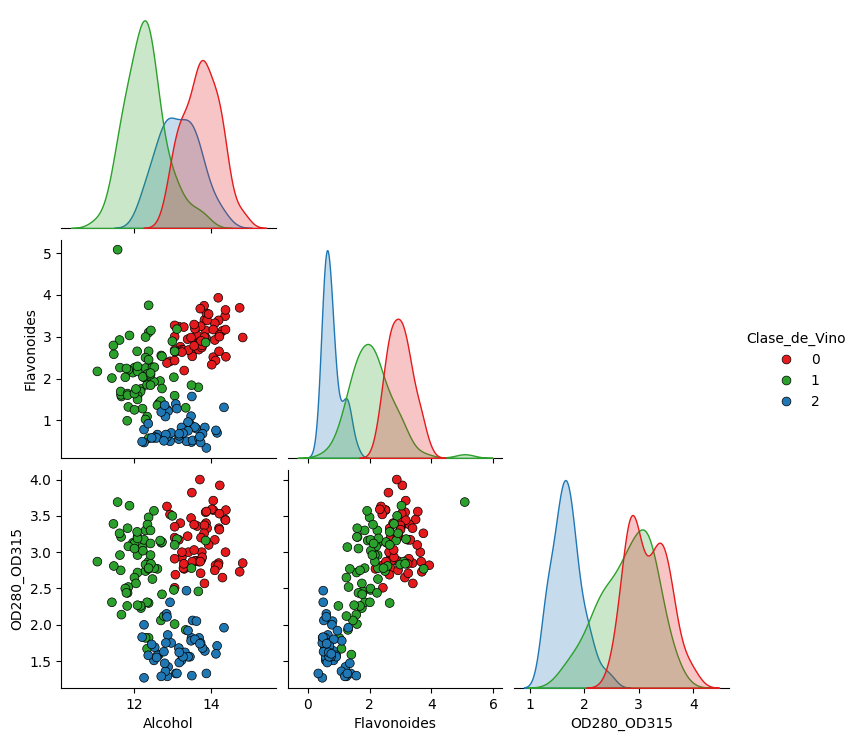

In [4]:
trio = ['Alcohol', 'Flavonoides', tercera]
pares = [('Alcohol', 'Flavonoides'), (tercera, 'Alcohol'), (tercera, 'Flavonoides')]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (a, b) in zip(axes, pares):
    sns.scatterplot(x=X[a], y=X[b], hue=y, palette=['#E41A1C', '#2CA02C', '#1F77B4'],
                    edgecolor='k', s=50, ax=ax)
    ax.set_title(f"{a} vs {b}")
    ax.legend(title='Clase')
plt.tight_layout()
plt.show()

g = sns.pairplot(df[trio + ['Clase_de_Vino']], hue='Clase_de_Vino',
                 palette=['#E41A1C', '#2CA02C', '#1F77B4'], corner=True,
                 plot_kws={'edgecolor': 'k', 's': 40})
plt.show()

Se nota que en Alcohol vs Flavonoides las tres clases quedan bastante separadas. En los pares con OD280_OD315 la clase 2 (azul) se aísla bien, pero las clases 0 y 1 se mezclan más, sobre todo con Flavonoides, porque esas dos variables suben juntas.

## 4. Entrenar y evaluar los 3 modelos

Entrené cada modelo con cada par de características (solo 2 columnas, para poder dibujar las fronteras). Usé la misma partición de la clase: 70% para entrenar y 30% para evaluar. También escalé los datos para que la comparación sea justa.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

def crear_modelos():
    return {
        'k-NN': KNeighborsClassifier(n_neighbors=5),
        'Árbol de Decisión': DecisionTreeClassifier(max_depth=4, random_state=42),
        'Naive Bayes': GaussianNB(),
    }

filas = []
modelos_entrenados = {}

for (a, b) in pares:
    scaler = StandardScaler().fit(X_train[[a, b]])
    Xtr = scaler.transform(X_train[[a, b]])
    Xte = scaler.transform(X_test[[a, b]])
    for nombre, modelo in crear_modelos().items():
        modelo.fit(Xtr, y_train)
        acc = (modelo.predict(Xte) == y_test).mean()
        filas.append({'Par': f"{a} + {b}", 'Modelo': nombre, 'Exactitud': acc})
        modelos_entrenados[((a, b), nombre)] = (modelo, scaler)

resultados = pd.DataFrame(filas)
tabla = resultados.pivot(index='Par', columns='Modelo', values='Exactitud')
print("Exactitud en el conjunto de prueba (%):")
display((tabla * 100).round(1))

Exactitud en el conjunto de prueba (%):


Modelo,Naive Bayes,k-NN,Árbol de Decisión
Par,,,
Alcohol + Flavonoides,90.7,88.9,88.9
OD280_OD315 + Alcohol,81.5,83.3,83.3
OD280_OD315 + Flavonoides,88.9,92.6,83.3


## 5. Fronteras de decisión

Cada fila es un par de características y cada columna un modelo. Los puntos son las botellas de entrenamiento y el color de fondo es la clase que predice el modelo en esa zona. En el título de cada gráfica puse la exactitud.

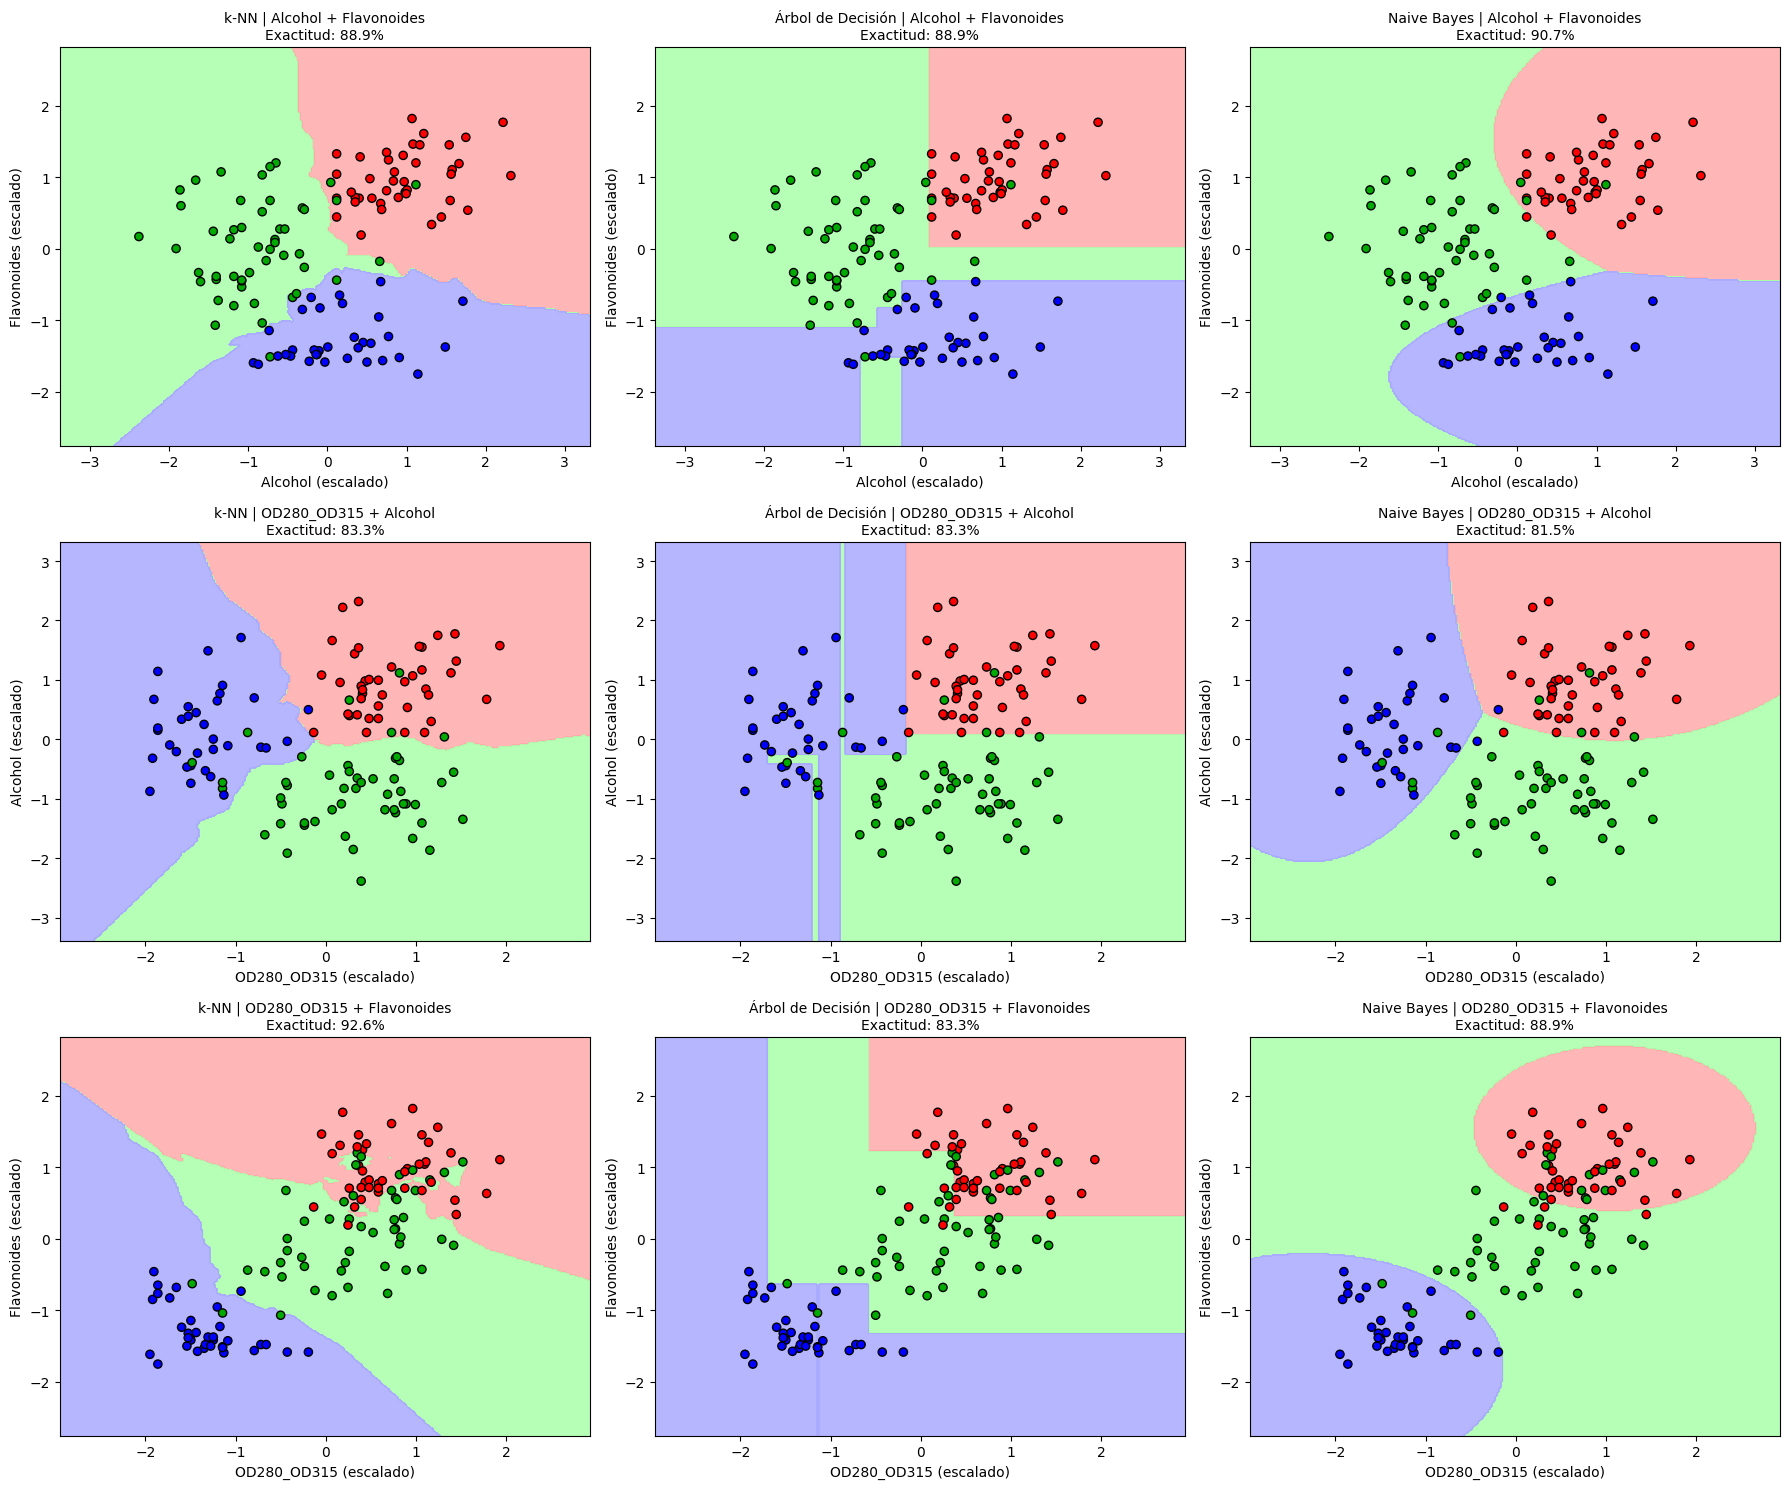

In [6]:
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00AA00', '#0000FF'])
nombres = list(crear_modelos().keys())

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
for i, (a, b) in enumerate(pares):
    for j, nombre in enumerate(nombres):
        modelo, scaler = modelos_entrenados[((a, b), nombre)]
        Xtr = scaler.transform(X_train[[a, b]])
        ax = axes[i, j]
        DecisionBoundaryDisplay.from_estimator(modelo, Xtr, cmap=cmap_light, ax=ax, alpha=0.85,
                                               grid_resolution=300, response_method='predict')
        ax.scatter(Xtr[:, 0], Xtr[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=35)
        ax.set_title(f"{nombre} | {a} + {b}\nExactitud: {tabla.loc[f'{a} + {b}', nombre]*100:.1f}%", fontsize=10)
        ax.set_xlabel(f"{a} (escalado)")
        ax.set_ylabel(f"{b} (escalado)")
plt.tight_layout()
plt.show()

## 6. Comparación final

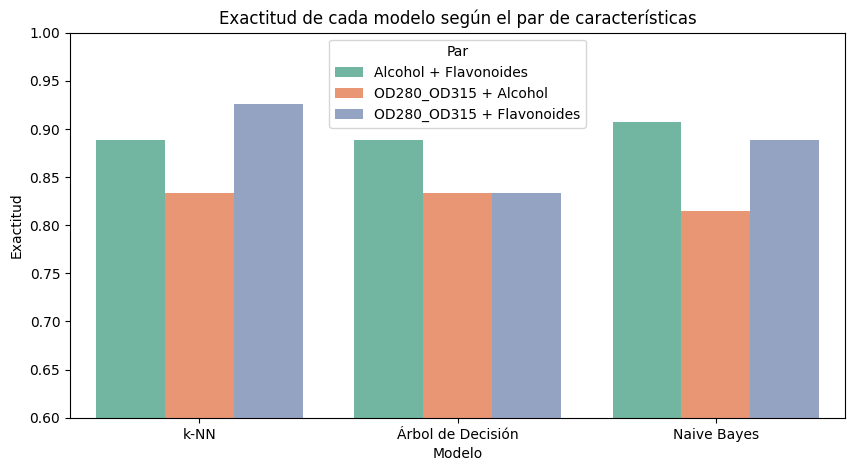

Promedio por modelo (%):


Modelo
Naive Bayes          87.0
k-NN                 88.3
Árbol de Decisión    85.2
Name: Exactitud, dtype: float64

Promedio por par (%):


Par
Alcohol + Flavonoides        89.5
OD280_OD315 + Alcohol        82.7
OD280_OD315 + Flavonoides    88.3
Name: Exactitud, dtype: float64

In [7]:
plt.figure(figsize=(10, 5))
sns.barplot(data=resultados, x='Modelo', y='Exactitud', hue='Par', palette='Set2')
plt.ylim(0.6, 1.0)
plt.title('Exactitud de cada modelo según el par de características')
plt.show()

print("Promedio por modelo (%):")
display((resultados.groupby('Modelo')['Exactitud'].mean() * 100).round(1))
print("Promedio por par (%):")
display((resultados.groupby('Par')['Exactitud'].mean() * 100).round(1))

## Conclusión

La tercera característica más representativa es **OD280_OD315**, con una correlación de -0.79 con la clase.

Sobre los pares, el que mejor separa las clases es Alcohol + Flavonoides (promedio de 89.5% entre los tres modelos). Con OD280_OD315 + Flavonoides la clase 2 queda muy separada, pero las clases 0 y 1 se mezclan porque esas dos variables están relacionadas entre sí (0.79) y dan información parecida.

Sobre los modelos, el que se ve más claro es **Naive Bayes**. Dibuja una zona suave y continua para cada clase, sin islas ni bordes raros, y se entiende de un vistazo. Además fue el mejor en Alcohol + Flavonoides (90.7%).

k-NN tuvo el promedio más alto (88.3%) y el mejor resultado de todos (92.6% con OD280_OD315 + Flavonoides), pero sus bordes son irregulares y se pegan a cada punto, así que cuesta más leerlos. El Árbol de Decisión corta en rectángulos y a veces deja franjas muy delgadas, y tuvo la exactitud más baja (85.2% de promedio). Eso sí, es el más fácil de convertir en reglas del tipo "si pasa esto, entonces es tal clase".

Una aclaración: el conjunto de prueba tiene solo 54 botellas, así que una diferencia de 1 o 2 puntos es más o menos una botella. Por eso me fijé también en cómo se ven las fronteras y no solo en el porcentaje.